# Path Traversal in Biological Networks using BFS and DFS
**Admission Number:** 134976

This notebook explores a small undirected gene interaction network (genes 0–7) using
Breadth-First Search (BFS) and Depth-First Search (DFS), then reconstructs the path from
gene 0 (source) to gene 7 (destination) found by each algorithm.

## Starter code: the gene interaction network

In [1]:
from collections import deque

# Gene interaction network (undirected)
graph = {
    0: [1, 3],
    1: [0, 2],
    2: [1],
    3: [0, 4, 7],
    4: [3, 5, 6, 7],
    5: [4, 6],
    6: [4, 5, 7],
    7: [3, 4, 6],
}

SOURCE = 0
DESTINATION = 7

## Part A: BFS traversal
BFS uses a **queue** (first in, first out). A gene is marked as seen when it is added to the
queue, so no gene is queued twice. Neighbours are taken in ascending order.

In [2]:
def bfs(graph, start):
    """Breadth-first traversal from `start`. Returns the order in which genes were visited."""
    visited = []
    seen = {start}
    queue = deque([start])

    while queue:
        gene = queue.popleft()
        visited.append(gene)
        print(f"Visiting gene {gene}")
        print(f"  Visited so far: {visited}")

        for neighbour in sorted(graph[gene]):
            if neighbour not in seen:
                seen.add(neighbour)
                queue.append(neighbour)

    return visited

## Part B: DFS traversal
DFS uses a **stack** (last in, first out). Neighbours are pushed in *reverse* ascending order
so that the smallest neighbour sits on top of the stack and is explored first. This gives the
same order as the recursive version of DFS.

In [3]:
def dfs(graph, start):
    """Depth-first traversal from `start`. Returns the order in which genes were visited."""
    visited = []
    stack = [start]

    while stack:
        gene = stack.pop()
        if gene in visited:
            continue
        visited.append(gene)
        print(f"Visiting gene {gene}")
        print(f"  Visited so far: {visited}")

        for neighbour in sorted(graph[gene], reverse=True):
            if neighbour not in visited:
                stack.append(neighbour)

    return visited

## Part C: Run both algorithms from gene 0

In [4]:
print("=== BFS ===")
bfs_path = bfs(graph, SOURCE)
print()
print("=== DFS ===")
dfs_path = dfs(graph, SOURCE)
print()
print("BFS final traversal path:", bfs_path)
print("DFS final traversal path:", dfs_path)

=== BFS ===
Visiting gene 0
  Visited so far: [0]
Visiting gene 1
  Visited so far: [0, 1]
Visiting gene 3
  Visited so far: [0, 1, 3]
Visiting gene 2
  Visited so far: [0, 1, 3, 2]
Visiting gene 4
  Visited so far: [0, 1, 3, 2, 4]
Visiting gene 7
  Visited so far: [0, 1, 3, 2, 4, 7]
Visiting gene 5
  Visited so far: [0, 1, 3, 2, 4, 7, 5]
Visiting gene 6
  Visited so far: [0, 1, 3, 2, 4, 7, 5, 6]

=== DFS ===
Visiting gene 0
  Visited so far: [0]
Visiting gene 1
  Visited so far: [0, 1]
Visiting gene 2
  Visited so far: [0, 1, 2]
Visiting gene 3
  Visited so far: [0, 1, 2, 3]
Visiting gene 4
  Visited so far: [0, 1, 2, 3, 4]
Visiting gene 5
  Visited so far: [0, 1, 2, 3, 4, 5]
Visiting gene 6
  Visited so far: [0, 1, 2, 3, 4, 5, 6]
Visiting gene 7
  Visited so far: [0, 1, 2, 3, 4, 5, 6, 7]

BFS final traversal path: [0, 1, 3, 2, 4, 7, 5, 6]
DFS final traversal path: [0, 1, 2, 3, 4, 5, 6, 7]


## Part D: Path from gene 0 to gene 7
Each traversal is extended to record the **parent** of every gene, i.e. the gene it was first
reached from. Walking back from gene 7 through the parents to gene 0 and reversing gives the path.

In [5]:
def bfs_with_parents(graph, start):
    """BFS that also records the parent of each gene."""
    visited = []
    parent = {start: None}
    queue = deque([start])

    while queue:
        gene = queue.popleft()
        visited.append(gene)
        for neighbour in sorted(graph[gene]):
            if neighbour not in parent:
                parent[neighbour] = gene
                queue.append(neighbour)

    return visited, parent


def dfs_with_parents(graph, start):
    """DFS that also records the parent of each gene."""
    visited = []
    parent = {}
    stack = [(start, None)]          # (gene, gene it was reached from)

    while stack:
        gene, came_from = stack.pop()
        if gene in parent:
            continue
        parent[gene] = came_from
        visited.append(gene)
        for neighbour in sorted(graph[gene], reverse=True):
            if neighbour not in parent:
                stack.append((neighbour, gene))

    return visited, parent


def reconstruct_path(parent, start, end):
    """Follow parent links back from `end` to `start` and return the path in order."""
    path = []
    gene = end
    while gene is not None:
        path.append(gene)
        gene = parent[gene]
    path.reverse()
    return path if path[0] == start else []

In [6]:
_, bfs_parent = bfs_with_parents(graph, SOURCE)
_, dfs_parent = dfs_with_parents(graph, SOURCE)

print("BFS parents:", dict(sorted(bfs_parent.items())))
print("DFS parents:", dict(sorted(dfs_parent.items())))
print()

bfs_route = reconstruct_path(bfs_parent, SOURCE, DESTINATION)
dfs_route = reconstruct_path(dfs_parent, SOURCE, DESTINATION)

print(f"BFS path {SOURCE} -> {DESTINATION}: {' -> '.join(map(str, bfs_route))}"
      f"  ({len(bfs_route) - 1} interactions)")
print(f"DFS path {SOURCE} -> {DESTINATION}: {' -> '.join(map(str, dfs_route))}"
      f"  ({len(dfs_route) - 1} interactions)")

BFS parents: {0: None, 1: 0, 2: 1, 3: 0, 4: 3, 5: 4, 6: 4, 7: 3}
DFS parents: {0: None, 1: 0, 2: 1, 3: 0, 4: 3, 5: 4, 6: 5, 7: 6}

BFS path 0 -> 7: 0 -> 3 -> 7  (2 interactions)
DFS path 0 -> 7: 0 -> 3 -> 4 -> 5 -> 6 -> 7  (5 interactions)


**Result:**

| Algorithm | Path from gene 0 to gene 7 | Interactions (edges) |
|-----------|----------------------------|----------------------|
| BFS | 0 → 3 → 7 | 2 |
| DFS | 0 → 3 → 4 → 5 → 6 → 7 | 5 |

## Visualising the traversals
The network figures are drawn with **Bokeh**, so they are interactive: hover over a gene to see
when it was visited, which gene it was reached from and which genes it interacts with.
The summary charts are drawn with **Seaborn**.
BFS is shown in **blue** and DFS in **orange**; grey genes have not been visited yet.
(If the libraries are missing, install them with `pip install bokeh seaborn pandas`.)

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bokeh.io import output_notebook, show
from bokeh.layouts import gridplot, row
from bokeh.models import ColumnDataSource, HoverTool
from bokeh.plotting import figure

output_notebook(hide_banner=True)
sns.set_theme(style="whitegrid", context="notebook")

# Fixed layout so every figure draws the genes in the same place
pos = {
    0: (0.0, 0.0), 1: (1.0, 1.2), 2: (2.0, 1.9), 3: (1.0, -0.8),
    4: (2.3, -0.1), 5: (3.5, 0.9), 6: (3.8, -0.7), 7: (2.5, -1.7),
}
edges = sorted({tuple(sorted((g, n))) for g, ns in graph.items() for n in ns})

BFS_COLOR, DFS_COLOR = "#2a78d6", "#eb6834"
UNVISITED, EDGE, INK, MUTED = "#d9d8d4", "#bdbcb6", "#0b0b0b", "#52514e"

bfs_order, bfs_parent = bfs_with_parents(graph, SOURCE)
dfs_order, dfs_parent = dfs_with_parents(graph, SOURCE)
bfs_route = reconstruct_path(bfs_parent, SOURCE, DESTINATION)
dfs_route = reconstruct_path(dfs_parent, SOURCE, DESTINATION)


def ordinal(n):
    return f"{n}{'tsnrhtdd'[(n // 10 % 10 != 1) * (n % 10 < 4) * n % 10::4]}"


def depth(parent, gene):
    """Number of edges from the start gene to `gene` along the parent links."""
    steps = 0
    while parent[gene] is not None:
        gene = parent[gene]
        steps += 1
    return steps


def tree_edges(order, parent, upto=None):
    """Edges from each visited gene back to the gene it was reached from."""
    genes = order[1:] if upto is None else order[1:upto + 1]
    return [(parent[g], g) for g in genes]


def network_figure(order=(), parent=None, colour=UNVISITED, highlight_edges=(), current=None,
                   notes=None, title="", width=440, height=340):
    """Interactive Bokeh drawing of the network with the genes in `order` coloured."""
    p = figure(title=title, width=width, height=height, x_range=(-0.6, 4.4), y_range=(-2.3, 2.4),
               tools="", toolbar_location=None)
    p.axis.visible = False
    p.grid.visible = False
    p.outline_line_color = None
    p.title.text_font_size = "11pt"

    def line_coords(edge_list):
        return ([[pos[a][0], pos[b][0]] for a, b in edge_list],
                [[pos[a][1], pos[b][1]] for a, b in edge_list])

    xs, ys = line_coords(edges)
    p.multi_line(xs, ys, line_color=EDGE, line_width=1.5)
    if highlight_edges:
        xs, ys = line_coords(highlight_edges)
        p.multi_line(xs, ys, line_color=colour, line_width=4)

    visited = list(order)
    genes = sorted(graph)
    source = ColumnDataSource(dict(
        x=[pos[g][0] for g in genes],
        y=[pos[g][1] for g in genes],
        label=[str(g) for g in genes],
        fill=[colour if g in visited else UNVISITED for g in genes],
        ink=["white" if g in visited else INK for g in genes],
        ring=[INK if g == current else "white" for g in genes],
        ring_width=[3 if g == current else 2 for g in genes],
        step=[ordinal(visited.index(g) + 1) if g in visited else "not yet" for g in genes],
        came_from=[("start" if parent[g] is None else f"gene {parent[g]}")
                   if parent and g in visited else "-" for g in genes],
        neighbours=[", ".join(map(str, graph[g])) for g in genes],
    ))
    nodes = p.scatter("x", "y", source=source, size=30, fill_color="fill",
                      line_color="ring", line_width="ring_width")
    p.text("x", "y", text="label", source=source, text_align="center", text_baseline="middle",
           text_color="ink", text_font_style="bold", text_font_size="11pt")
    if notes:
        p.text([pos[g][0] for g in notes], [pos[g][1] - 0.3 for g in notes], text=list(notes.values()),
               text_align="center", text_baseline="top", text_color=MUTED, text_font_size="8pt")
    p.add_tools(HoverTool(renderers=[nodes], tooltips=[
        ("Gene", "@label"), ("Visited", "@step"),
        ("Reached from", "@came_from"), ("Interacts with", "@neighbours"),
    ]))
    return p

### Figure 1: The gene interaction network (Bokeh)

In [8]:
show(network_figure(notes={SOURCE: "source", DESTINATION: "destination"},
                    title="Gene interaction network (8 genes, 10 interactions)",
                    width=560, height=420))

### Figure 2: Adjacency matrix (Seaborn)
The same network as a matrix: a dark cell means the two genes interact. Gene 4 has the most
interactions (4), and gene 2 the fewest (1).

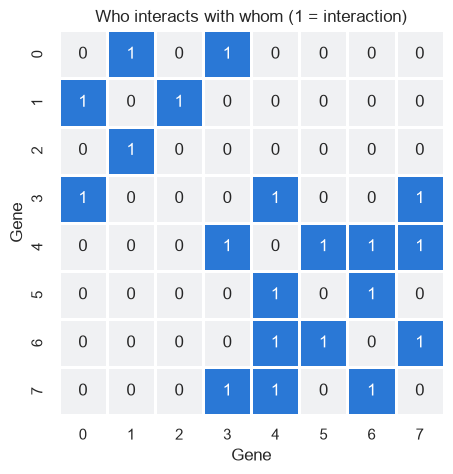

In [9]:
genes = sorted(graph)
adjacency = pd.DataFrame(0, index=genes, columns=genes)
for gene, neighbours in graph.items():
    adjacency.loc[gene, neighbours] = 1

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(adjacency, cmap=sns.light_palette(BFS_COLOR, as_cmap=True), annot=True, cbar=False,
            linewidths=2, linecolor="white", square=True, ax=ax)
ax.set_xlabel("Gene")
ax.set_ylabel("Gene")
ax.set_title("Who interacts with whom (1 = interaction)")
plt.show()

### Figure 3: Step-by-step traversal (Bokeh)
Each panel is one iteration. The gene with the black ring is the one being visited in that step;
the coloured edges show which gene each visited gene was reached from.

In [10]:
for name, order, parent, colour in [("BFS", bfs_order, bfs_parent, BFS_COLOR),
                                    ("DFS", dfs_order, dfs_parent, DFS_COLOR)]:
    panels = [network_figure(order[:step + 1], parent, colour,
                             highlight_edges=tree_edges(order, parent, step), current=order[step],
                             title=f"{name} step {step + 1}: visit gene {order[step]}\n"
                                   f"visited = {order[:step + 1]}",
                             width=300, height=250)
              for step in range(len(order))]
    show(gridplot(panels, ncols=4))

### Figure 4: Visit order and distance (Seaborn)
Each row lists the genes in the order the algorithm visited them. The cell colour is the gene's
distance (number of interactions) from gene 0 along that algorithm's search tree. BFS distances
only ever increase, because BFS finishes one level before starting the next; DFS jumps back to
distance 1 at gene 3 and then runs all the way to distance 5.

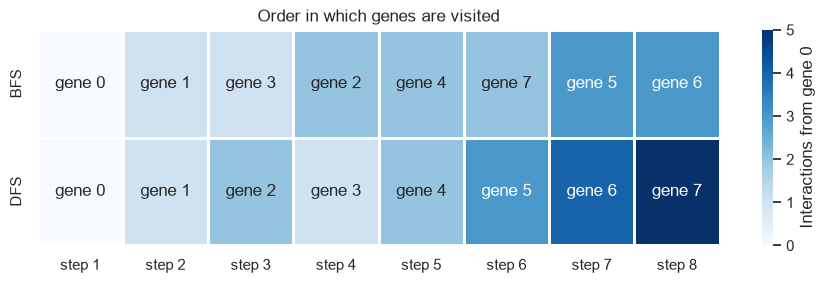

In [11]:
orders = {"BFS": bfs_order, "DFS": dfs_order}
parents = {"BFS": bfs_parent, "DFS": dfs_parent}
steps = [f"step {i + 1}" for i in range(len(bfs_order))]
distance = pd.DataFrame({alg: [depth(parents[alg], g) for g in order] for alg, order in orders.items()},
                        index=steps).T
labels = pd.DataFrame({alg: [f"gene {g}" for g in order] for alg, order in orders.items()},
                      index=steps).T

fig, ax = plt.subplots(figsize=(11, 2.8))
sns.heatmap(distance, annot=labels, fmt="", cmap="Blues", linewidths=2, linecolor="white",
            cbar_kws={"label": "Interactions from gene 0"}, ax=ax)
ax.set_title("Order in which genes are visited")
ax.set_ylabel("")
plt.show()

### Figure 5: BFS tree vs DFS tree (Bokeh)
The coloured edges form the *search tree*: every gene is connected to the gene it was first
reached from, and the note under each gene gives its visit order.
BFS builds a short, wide tree; DFS builds a long, deep one.

In [12]:
trees = [network_figure(order, parent, colour, highlight_edges=tree_edges(order, parent),
                        notes={g: f"{ordinal(i + 1)} visited" for i, g in enumerate(order)},
                        title=f"{name} search tree\norder = {order}")
         for name, order, parent, colour in [("BFS", bfs_order, bfs_parent, BFS_COLOR),
                                             ("DFS", dfs_order, dfs_parent, DFS_COLOR)]]
show(row(trees))

### Figure 6: Path from gene 0 to gene 7 (Bokeh)

In [13]:
paths = []
for name, route, parent, colour in [("BFS", bfs_route, bfs_parent, BFS_COLOR),
                                    ("DFS", dfs_route, dfs_parent, DFS_COLOR)]:
    path_edges = list(zip(route, route[1:]))
    paths.append(network_figure(route, parent, colour, highlight_edges=path_edges,
                                notes={SOURCE: "source", DESTINATION: "destination"},
                                title=f"{name} path: {' -> '.join(map(str, route))}\n"
                                      f"{len(path_edges)} interactions"))
show(row(paths))

### Figure 7: Distance of each gene from gene 0 (Seaborn)

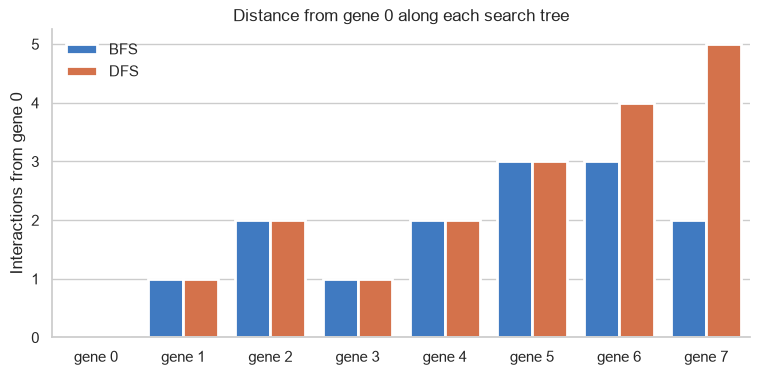

In [14]:
depths = pd.DataFrame([{"Gene": f"gene {g}", "Algorithm": alg, "Interactions from gene 0": depth(p, g)}
                       for alg, p in parents.items() for g in sorted(graph)])

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=depths, x="Gene", y="Interactions from gene 0", hue="Algorithm",
            palette={"BFS": BFS_COLOR, "DFS": DFS_COLOR}, edgecolor="white", linewidth=2, ax=ax)
ax.set_title("Distance from gene 0 along each search tree")
ax.set_xlabel("")
ax.legend(title="", frameon=False)
sns.despine()
plt.show()

BFS distances are the true shortest distances (gene 7 is only 2 interactions away), while DFS
reaches genes 6 and 7 through long chains (4 and 5 interactions).

## Part E: Comparing BFS and DFS

**Traversal orders**
- BFS: `[0, 1, 3, 2, 4, 7, 5, 6]`
- DFS: `[0, 1, 2, 3, 4, 5, 6, 7]`

**Why they differ.** BFS keeps the genes waiting to be explored in a **queue** (first in, first
out). After visiting gene 0 it queues both neighbours, 1 and 3, and processes them before anything
further away. So it moves outwards level by level: distance 0 (gene 0), distance 1 (1, 3),
distance 2 (2, 4, 7), then distance 3 (5, 6). Gene 7 is reached early, straight from gene 3.

DFS keeps them on a **stack** (last in, first out), which behaves the same as recursion. The most
recently discovered gene is always explored next, so DFS follows one branch as far as it goes
before backtracking. It goes 0 → 1 → 2, hits a dead end at gene 2, backtracks to 0, then goes
3 → 4 → 5 → 6 → 7. Because it keeps going deeper (from 4 to 5 before trying 7, then 5 to 6, then
6 to 7), gene 7 is reached last, through a long chain, even though 7 is a direct neighbour of 3 and 4.

**Shorter path.** **BFS** gave the shorter path: 0 → 3 → 7 with **2 interactions**, compared with
the DFS path 0 → 3 → 4 → 5 → 6 → 7 with **5 interactions**. In an unweighted graph BFS always finds
a shortest path, because it reaches every gene at distance *k* before any gene at distance *k + 1*.
DFS gives no such guarantee; its path depends on the order in which it explores branches.

## Part F: Reflection

**BFS: shortest signalling route.** BFS spreads outward one interaction at a time, like a signal
spreading from a gene to its direct partners, then to their partners, and so on. The path it finds
is the one with the fewest interactions, which is the most direct way information or a regulatory
effect can travel between two genes. The levels BFS produces also measure how far every gene is
from the source.
*Example question:* "What is the minimum number of regulatory steps for a transcription factor
(gene 0) to influence a target gene (gene 7)?" or "Which proteins lie within two interactions of a
disease protein?"

**DFS: exploring a whole pathway.** DFS follows one chain of interactions to its end before
backtracking. This matches tracing a complete pathway or cascade, for example following a
signalling or metabolic chain step by step to see everything downstream of a starting gene. DFS is
also the basis for finding connected components (groups of genes that interact only with each
other) and for detecting cycles such as feedback loops.
*Example question:* "Which genes are part of the downstream cascade triggered by a receptor
gene, and is there a feedback loop that leads back to it?"

In short, BFS answers **"how close?"** (shortest communication path), while DFS answers **"what
can be reached, and along which full routes?"** (pathway exploration).